# **Maestría en Inteligencia Artificial Aplicada**

## **Curso: Inteligencia Artificial y Aprendizaje Automático**

**Tecnológico de Monterrey**

**Prof Luis Eduardo Falcón Morales**

### **Actividad de Modelos basados en Árboles**

* **Nombre:** Ricardo Saldaña Morales

* **Matrícula:** A01841000

# **Introducción: Auditoría de modelos de riesgo crediticio basados en Árboles**



### **Contexto del problema:**

* Una startup de tecnología financiera (fintech) llamada CrediNova busca fortalecer su proceso de evaluación de riesgo para créditos de consumo. Actualmente, la empresa recibe miles de solicitudes cada mes y desea anticipar cuáles clientes podrían incumplir sus obligaciones financieras durante los próximos 90 días.

* Dichos clientes ya tienen una relación vigente con la institución, con la cual ya poseen uno o más productos financieros activos. Se desea predecir, al momento de la evaluación (para otorgar o revisar un crédito), cuáles de dichos clientes caerán en incumplimiento de algunos de sus pagos durante los siguientes 90 días.

* Un analista junior del área de ciencia de datos bajo su propia iniciativa desarrolló la solución que se encuentra en este cuaderno de Jupyter, la cual está basada en modelos de árboles. Se dio a la tarea de conjuntar la información histórica con diversas áreas de la empresa y generar la base de datos que se encuentra en el archivo "fintech_default_risk.csv". Dicho archivo lo encuentras en Canvas.  

* Los resultados que se obtienen al ejecutar el código se ven bastante prometedores, tan es así, que el CEO desea autorizar su despliegue a producción lo antes posible. Sin embargo, la dirección de riesgos desea realizar antes una última validación de la propuesta. Siendo tú un científico de datos senior, te encargan realizar una auditoría forense de este cuaderno.  

* En particular, se espera que cumplas con los siguientes objetivos:

  * Puedes modificar el cuaderno (celdas de texto y código) tanto como lo consideres necesario, salvo donde se te indique.

  * Identificar y documentar al menos 6 errores conceptuales o metodológicos en la propuesta actual.
  
  * Detectar posibles fuentes de fuga de información (data leakage) tanto en los datos como en el proceso de ajuste y entrenamiento de los modelos.

  * Justificar el uso de la métrica, y en su caso, evaluar la pertinencia de proponer y usar otras métricas.

  * Identificar evidencia de sub o sobreentrenamiento con respecto a la métrica en cuestión.

  * Analizar el impacto de la selección del umbral de clasificación sobre los resultados del negocio.

  * Decidir cuál de los 3 modelos de árboles consideras el más adecuado para desplegar en producción.

  * Identificar los 3 o 4 factores más importantes del mejor modelo obtenido. Explicar sus significados en el contexto de negocio.

  * Realizar un reporte del resultado de la auditoría forense comprensible para los tomadores de decisiones. En particular, indicar si el modelo se puede desplegar en producción como lo propone el analista junior, o cuál serían en dado caso las recomendaciones.

  * Reportar las herramientas de IA generativa (LLMs) utilizadas como apoyo para la auditoría.
  

### **Descripción del negocio:**

* Cada vez que una solicitud de crédito es aprobada:
   * Si el cliente paga correctamente, la empresa obtiene una utilidad neta estimada de $100 USD.

   * Si el cliente entra en incumplimiento, la empresa enfrenta una pérdida promedio estimada de $500 USD.

* Por este motivo, el objetivo no consiste únicamente en maximizar métricas estadísticas, sino en maximizar el valor económico esperado para la organización. Por ello, como parte del análisis, también deberás estimar:
   * La utilidad esperada utilizando el umbral estándar de clasificación (0.5).

   * La utilidad esperada utilizando un umbral optimizado.
   
   * El impacto económico estimado por cada 10,000 solicitudes evaluadas.

# **Cargando y conociendo la información**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
import shap

from sklearn.metrics import (ConfusionMatrixDisplay,
                             classification_report,
                             confusion_matrix,
                             make_scorer,
                             accuracy_score,
                             RocCurveDisplay,
                             PrecisionRecallDisplay,
                             roc_auc_score,
                             precision_recall_curve,
                             average_precision_score,
                             auc,
                             roc_curve,
                             recall_score)

from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict, cross_validate, validation_curve
from imblearn.pipeline import Pipeline   # permite aplicar SMOTE solo dentro de cada fold de entrenamiento


RANDOM_STATE = 11   # No modificar el valor de esta semilla.
                    # Siempre que aparezca esta semilla, seguirla utilizando,
                    # inclusive con modelos o cualquier otra función o método.

In [2]:
# Cargamos los datos y obtenemos alguna información básica:

df = pd.read_csv('fintech_default_risk.csv')

print("Dimensión:", df.shape)
print("-"*25)
print('Variables involucradas:')
print(df.head(3).T)

print("\n")
print("-"*25)
print("Distribución objetivo:")
print(df["default_90d"].value_counts(normalize=True))


Dimensión: (5000, 14)
-------------------------
Variables involucradas:
                                         0             1             2
edad                             46.000000     37.000000     48.000000
ingreso_mensual               34959.928315   8659.826698  11502.487602
antiguedad_laboral_meses        296.000000      6.000000    166.000000
score_crediticio                659.093869    728.456721    636.261824
utilizacion_credito               0.410414      0.882132      0.408709
atrasos_12m                       3.000000      1.000000      1.000000
consultas_buro_6m                 5.000000      2.000000      3.000000
num_productos                     7.000000      3.000000      1.000000
limite_credito               209105.311645  44070.504292  42132.236007
deuda_total                   77661.271706  42105.837892  15409.496357
relacion_deuda_ingreso            2.221373      4.861642      1.339550
dias_max_atraso_30d_despues       7.000000      4.000000      3.000000
clien

In [3]:
# Definimos nuestras variables de entrada y la objetivo:

target = "default_90d"

X = df.drop(columns=[target])
y = df[target]

In [4]:
# Debido al desbalanceo de clases, aplicaremos una técnica de balanceo de clases.

smote = SMOTE(random_state=RANDOM_STATE   # semilla
              )

X_res, y_res = smote.fit_resample(X, y) # Balanceamos las clases con valores predeterminados de SMOTE.

X_train, X_test, y_train, y_test = train_test_split(
    X_res,
    y_res,
    test_size=0.30,  # Usemos una partición 70%-30%, pero podría ajustarse, en dado caso.
    random_state=RANDOM_STATE  # semilla
)

**Observación:** En el código anterior se observa que SMOTE se aplica a las observaciones antes de la partición en los conjuntos de entrenamiento y prueba. El balanceo sólo debe aplicarse al conjunto de entrenamiento.

# **Configuración y Entrenamiento de los Modelos**

In [5]:
# --- Modelo 1: Árbol de decisión ---
dt = DecisionTreeClassifier(random_state=RANDOM_STATE  # semilla
                            )
dt.fit(X_train, y_train)

# --- Modelo 2: Random Forest ---
rf = RandomForestClassifier(random_state=RANDOM_STATE  # semilla
                            )
rf.fit(X_train, y_train)

# --- Modelo 3: XGBoost ---
xgb = XGBClassifier(eval_metric='logloss',   # métrica caso binario
                    random_state=RANDOM_STATE  # semilla
                    )
xgb.fit(X_train, y_train)


# Obtenemos los desempeños, verificando que no estén sobreentrenados,
# ni subentrenados:
modelos = {
    "Árbol de Decisión": dt,
    "Random Forest": rf,
    "XGBoost": xgb
}

y_probs = []   # Guardemos las probabilidades para uso posterior:
               # 0:DT, 1:RF, 2:XGBoost
print("Desempeño de los modelos:")
print("+"*25)
for nombre, modelo in modelos.items():

    y_pred_train = modelo.predict(X_train)
    y_pred_test = modelo.predict(X_test)
    y_probs.append(modelo.predict_proba(X_test)[:,1])

    # Verificando en los conjuntos de Train y Test:
    acc_train = accuracy_score(y_train, y_pred_train)
    acc_test = accuracy_score(y_test, y_pred_test)

    print(f"{nombre}:")

    print(f"Train: {acc_train:.4f}")
    print(f"Test: {acc_test:.4f}")
    print("+"*20)

Desempeño de los modelos:
+++++++++++++++++++++++++
Árbol de Decisión:
Train: 1.0000
Test: 1.0000
++++++++++++++++++++
Random Forest:
Train: 1.0000
Test: 1.0000
++++++++++++++++++++
XGBoost:
Train: 1.0000
Test: 1.0000
++++++++++++++++++++


**Observación:** A pesar de tener un accuracy de 1 en todos los modelos, es importante revisar otras métricas complementarias.

# **Importancia e Interpretabilidad de los Factores o Características:**

**En realidad solo debiéramos hacer el análisis de los mejores factores para el mejor modelo encotrado, pero como todos resultaron con el mejor desempeño, incluímos los tres casos a continuación como referencia.**

In [6]:
# Modelo de Árbol de Decisión (decision tree-dt):

importancias = dt.feature_importances_

# Creamos el DataFrame para ordenarlas y visualizarlas mejor:
df_importancias = pd.DataFrame({
    'Característica:': X.columns,
    'Importancia': importancias
}).sort_values(by='Importancia', ascending=False)

print(df_importancias)

                Característica:  Importancia
11  dias_max_atraso_30d_despues          1.0
1               ingreso_mensual          0.0
2      antiguedad_laboral_meses          0.0
3              score_crediticio          0.0
0                          edad          0.0
4           utilizacion_credito          0.0
5                   atrasos_12m          0.0
7                 num_productos          0.0
6             consultas_buro_6m          0.0
8                limite_credito          0.0
9                   deuda_total          0.0
10       relacion_deuda_ingreso          0.0
12              cliente_premium          0.0


In [7]:
# Modelo Bosque Aleatorio (Random Forest-rf):

importancias = pd.DataFrame({
    "Variable": X_train.columns,
    "Importancia": rf.feature_importances_
})

importancias = importancias.sort_values(
    "Importancia",
    ascending=False
)

print(importancias.head(10))

                       Variable  Importancia
11  dias_max_atraso_30d_despues     0.822857
4           utilizacion_credito     0.058264
3              score_crediticio     0.025473
10       relacion_deuda_ingreso     0.023019
6             consultas_buro_6m     0.018116
12              cliente_premium     0.011584
7                 num_productos     0.008276
9                   deuda_total     0.007900
2      antiguedad_laboral_meses     0.006443
0                          edad     0.005921


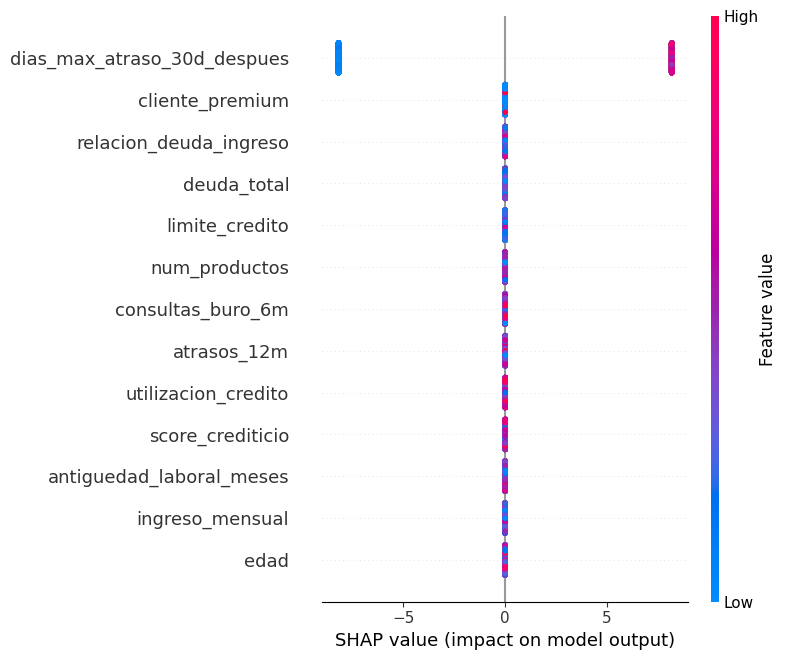

In [8]:
# Modelo XGBoost:

explainer = shap.TreeExplainer(xgb)

shap_values = explainer.shap_values(X_test)

shap.summary_plot(
    shap_values,
    X_test
)

## **Seleccionemos y analicemos un cliente en Particular:**

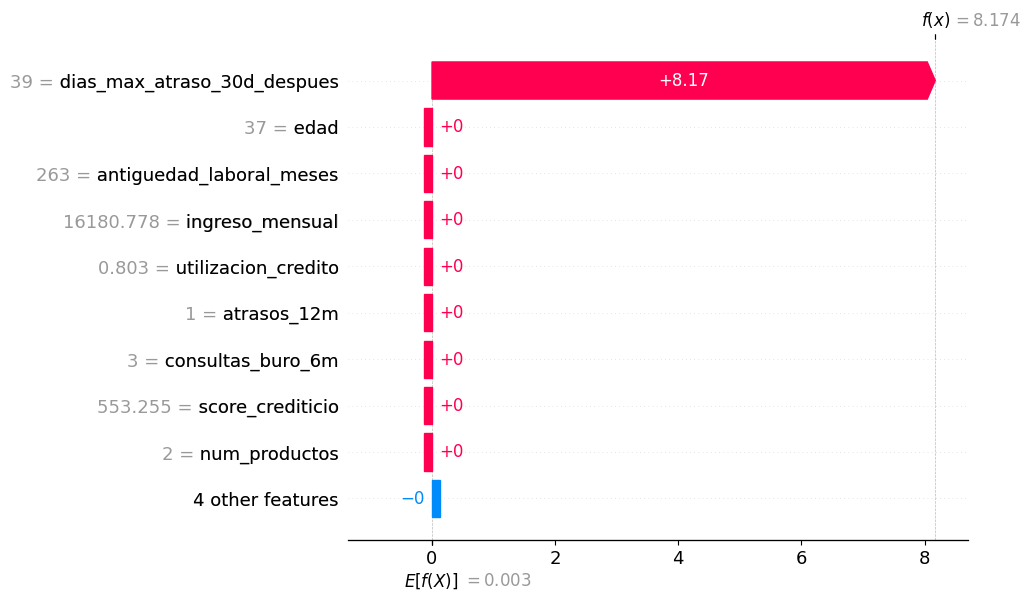

In [9]:
# Analicemos a un cliente en particular con XGBoost:

cliente = X_test.iloc[[11]]
shap_values_cliente = explainer.shap_values(cliente)

shap.plots.waterfall(
    shap.Explanation(
        values=shap_values_cliente[0],
        base_values=explainer.expected_value,
        data=cliente.iloc[0],
        feature_names=cliente.columns
    )
)

**Interpretación del gráfico:**

* El factor de riesgo principal (máximo días de atraso en alguno de sus pagos durante los 30 días siguientes a la evaluación) termina siendo determinante, lo que resulta en una predicción de riesgo final (en escala log-odds) de  f(x)=8.174  (muy por encima del promedio E[f(X)]=0.003). Así, si el umbral de aprobación fuera el estándar de 0.50, este cliente sería rechazado.

**Observación:** El cliente revisado es un registro sintético que generó SMOTE. El valor base E[f(X)] = 0.003 en log-odds equivale a una probabilidad de incumplimiento de 50%, que es cercana a la proporción del conjunto balanceado, no de la cartera de CrediNova (11.7%).

# **Análisis desde la perspectiva del negocio:**

In [10]:
GANANCIA_BUENO = 100
PERDIDA_DEFAULT = -500


In [11]:
# Función de utilidad:

# Considerando el umbral estándar:
threshold = 0.5

def utilidad(y_true, y_prob, threshold):

    aprobar = y_prob < threshold

    utilidad_total = 0

    for real, aprobado in zip(y_true, aprobar):

        if aprobado:

            if real == 0:
                utilidad_total += 100

            else:
                utilidad_total -= 500

    return utilidad_total



# Mejor modelo encontrado:
y_probs_mejor_modelo = y_probs[2]   # XGBoost

utilidad_05 = utilidad(
    y_test,
    y_probs_mejor_modelo,
    threshold=0.5
)

print("Mayor Utilidad (USD) con umbral 0.5:")
print(utilidad_05)

Mayor Utilidad (USD) con umbral 0.5:
132700


Mejor umbral: 0.01
Mayor Utilidad (USD): 132700


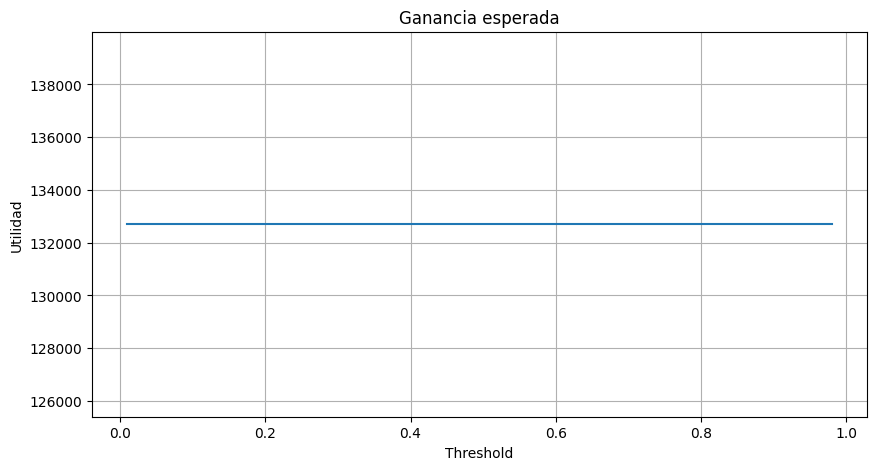

In [12]:
# Ajustando para buscar el mejor umbral óptimo:

thresholds = np.arange(
    0.01,
    0.99,
    0.01
)

utilidades = []

for th in thresholds:

    u = utilidad(
        y_test,
        y_probs_mejor_modelo,
        threshold=th
    )

    utilidades.append(u)

best_idx = np.argmax(utilidades)

best_threshold = thresholds[best_idx]

best_profit = utilidades[best_idx]

print('Mejor umbral:',best_threshold)
print('Mayor Utilidad (USD):',best_profit)



# Grafiquemos Umbral vs Utilidad:

plt.figure(figsize=(10,5))

plt.plot(
    thresholds,
    utilidades
)

plt.xlabel("Threshold")
plt.ylabel("Utilidad")
plt.title("Ganancia esperada")
plt.grid()

plt.show()

In [13]:
# Calculamos ahora la utilidad por cada 10,000 solicitudes:


def utilidad_por_10000(y_true, y_prob, threshold):

    aprobados = y_prob < threshold

    utilidad = 0
    total_aprobados = 0

    for real, aprobado in zip(y_true, aprobados):

        if aprobado:

            total_aprobados += 1

            if real == 0:
                utilidad += GANANCIA_BUENO

            else:
                utilidad += PERDIDA_DEFAULT

    # Escalamos a 10,000 solicitudes:
    utilidad_escalada = utilidad * (
        10_000 / len(y_true)
    )

    return utilidad_escalada



In [14]:
profit_default = utilidad_por_10000(
    y_test,
    y_probs_mejor_modelo,
    threshold=0.50
)

profit_optimal = utilidad_por_10000(
    y_test,
    y_probs_mejor_modelo,
    threshold=best_threshold
)

delta = profit_optimal - profit_default

incremento_pct = (
    delta /
    abs(profit_default)
) * 100

print(f"Threshold 0.50 : ${profit_default:,.0f}")
print(f"Threshold óptimo : ${profit_optimal:,.0f}")
print(f"Diferencia : ${delta:,.0f}")
print(f"Incremento : {incremento_pct:.1f}%")

Threshold 0.50 : $500,944
Threshold óptimo : $500,944
Diferencia : $0
Incremento : 0.0%


## **Matriz de Confusión**



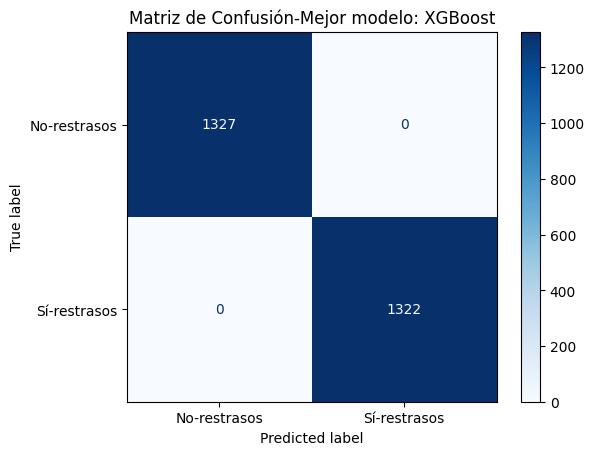

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay

class_names = ["No-restrasos", "Sí-restrasos"]
y_pred = modelo.predict(X_test)

disp = ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=class_names, cmap=plt.cm.Blues
)
plt.title(f"Matriz de Confusión-Mejor modelo: {nombre}")
plt.show()

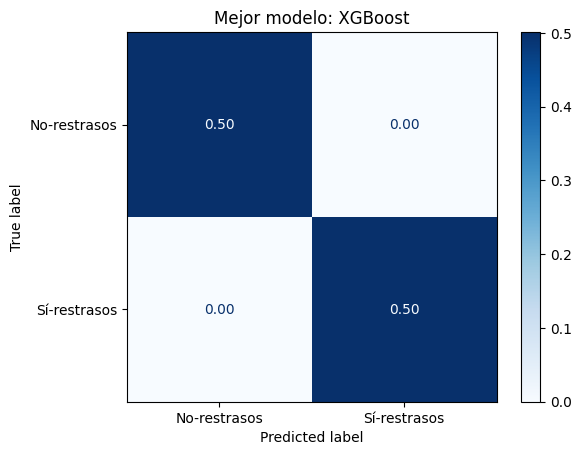

In [16]:
# O bien en su forma de proporciones:
disp = ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=class_names,
    cmap=plt.cm.Blues,
    normalize='all',  # Normalizando con respecto al total de datos.
    values_format='.2f' # Total de decimales desplegadas.
)
plt.title(f"Mejor modelo: {nombre}")
plt.show()

**Observaciones:**

*   Las 98 opciones  de umbrales dan la misma utilidad de \$132,700 porque el modelo clasifica correctamente debido al data leakage.
*   El umbral se busca sobre el conjunto de prueba.
*   La utilidad por 10,000 solicitudes se calcula sobre el conjunto de prueba que tiene 50% de incumplimientos y 44% de registros sintéticos que no representan la cartera real.
*   Las matrices de confusión utilizan las variables *modelo* y *nombre* que fueron definidas en la última iteración del for, es decir, del XGBoost.
*   Usa el umbral 0.5 para la matriz de confusión y no el umbral óptimo que se calculó.




# **Documentación de las observaciones de auditoría**

En esta sección se detallan las observaciones a la solución propuesta.

**Observación 1**

Se identificó que la variable dias_max_atraso_30d_despues contiene información sobre los atrasos registrados durante los 30 días posteriores a la evaluación del crédito. Esto representa una fuga de información, ya que dichos datos no estarían disponibles al momento de realizar la predicción.

Al analizar esta variable individualmente, se obtuvo un AUC de 1, lo que significa que permite distinguir perfectamente entre clientes que incumplieron y aquellos que no lo hicieron en la muestra disponible. De hecho, el árbol de decisión logró clasificar todos los registros utilizando únicamente esta variable.

**Impacto:** La inclusión de información futura explica el desempeño perfecto de los modelos y genera resultados que no serían reproducibles en condiciones reales de operación.

**Corrección propuesta:** Excluir esta variable del entrenamiento y verificar que todas las variables restantes correspondan a información disponible en la fecha de evaluación del crédito.

In [17]:
from sklearn.metrics import roc_auc_score

auc_univariado = {}
for col in X.columns:
    auc_col = roc_auc_score(y, df[col])
    auc_univariado[col] = max(auc_col, 1 - auc_col)   # sin importar la dirección

print("AUC univariado de cada variable (base original, sin SMOTE):")
print(pd.Series(auc_univariado).sort_values(ascending=False).round(3))

AUC univariado de cada variable (base original, sin SMOTE):
dias_max_atraso_30d_despues    1.000
utilizacion_credito            0.700
relacion_deuda_ingreso         0.673
consultas_buro_6m              0.662
deuda_total                    0.630
score_crediticio               0.630
atrasos_12m                    0.550
limite_credito                 0.523
antiguedad_laboral_meses       0.514
edad                           0.505
cliente_premium                0.505
ingreso_mensual                0.502
num_productos                  0.501
dtype: float64


In [18]:
# Comparamos la variable sospechosa entre clientes que pagan y los que caen en default:
print(df.groupby(target)["dias_max_atraso_30d_despues"].describe().round(1))

print("\nMáximo de días de atraso entre los que NO cayeron en default:",
      df.loc[df[target] == 0, "dias_max_atraso_30d_despues"].max())
print("Mínimo de días de atraso entre los que SÍ cayeron en default:",
      df.loc[df[target] == 1, "dias_max_atraso_30d_despues"].min())

# El árbol del analista junior en realidad es una sola regla:
print(f"\nProfundidad del árbol original: {dt.get_depth()}  |  Hojas: {dt.get_n_leaves()}")
print(f"Regla aprendida: {X.columns[dt.tree_.feature[0]]} <= {dt.tree_.threshold[0]:.1f}")

              count  mean   std   min   25%   50%   75%   max
default_90d                                                  
0            4414.0   4.5   2.8   0.0   2.0   4.0   7.0   9.0
1             586.0  52.5  21.0  15.0  35.0  52.0  70.0  89.0

Máximo de días de atraso entre los que NO cayeron en default: 9
Mínimo de días de atraso entre los que SÍ cayeron en default: 15

Profundidad del árbol original: 1  |  Hojas: 2
Regla aprendida: dias_max_atraso_30d_despues <= 12.0


**Observación 2**

El analista utilizó SMOTE para balancear las clases antes de dividir la información en los conjuntos de entrenamiento y prueba, lo cual es incorrecto ya que permite que la generación de observaciones sintéticas utilice información que posteriormente formará parte del conjunto de prueba.

Con esto, se identificó que 1,162 registros del conjunto de prueba (43.9%) eran observaciones sintéticas.

**Impacto:** Los resultados de la evaluación pueden estar sesgados, ya que los modelos se prueban con información que no es completamente independiente de los datos utilizados en el entrenamiento.

**Corrección propuesta:** Separar primero los conjuntos de entrenamiento y prueba. Después aplicar SMOTE sólo en el conjunto de entrenamiento y dentro de cada partición de la validación cruzada.

In [19]:
# Identificamos los registros sintéticos en test
sinteticos = X_test.index >= len(df)

print("Total de registros:", len(X_test))
print("Registros sintéticos:", sinteticos.sum())
print(f"Porcentaje sintético: {sinteticos.mean():.1%}")

Total de registros: 2649
Registros sintéticos: 1162
Porcentaje sintético: 43.9%


**Observación 3**

Como consecuencia de la aplicación de SMOTE antes de dividir los datos, el conjunto de prueba presenta una proporción de incumplimientos cercana al 50%, mientras que en la base original esta proporción es de 11.7%.

Esta diferencia es relevante porque el objetivo del modelo es evaluar clientes con características semejantes a las de la cartera real. Por lo tanto, utilizar una muestra artificialmente equilibrada puede distorsionar la interpretación de los resultados, especialmente aquellos relacionados con las decisiones de aprobación y el impacto económico.

**Impacto:** Las métricas y estimaciones de utilidad obtenidas sobre este conjunto de prueba no representan adecuadamente el comportamiento esperado de la cartera.

**Corrección propuesta:** Realizar una partición estratificada de la base original, conservando aproximadamente la misma proporción de clientes con y sin incumplimiento en ambos conjuntos.

In [20]:
# Comparamos las tasas de incumplimiento
print(f"Base original: {y.mean():.1%}")
print(f"Conjunto de prueba: {y_test.mean():.1%}")

Base original: 11.7%
Conjunto de prueba: 49.9%


**Observación 4**

El analista utilizó el accuracy para evaluar los tres modelos. Sin embargo, esta métrica no resulta suficiente para el problema planteado, debido al desbalance entre las clases y a las diferencias económicas entre los posibles errores de clasificación.

En la base original, el 88.28% de los clientes no presenta incumplimiento. Por lo tanto, un modelo que clasificara a todos los clientes como buenos alcanzaría un accuracy de 88.28%, aunque no identificaría ninguno de los incumplimientos.

Esto demuestra que un porcentaje elevado de aciertos no necesariamente implica que el modelo sea útil para evaluar el riesgo crediticio.

**Impacto:** La evaluación puede favorecer modelos con una elevada proporción de clasificaciones correctas, pero con poca capacidad para identificar clientes riesgosos.

**Corrección propuesta:** Complementar la evaluación con métricas como recall, AUC-ROC y PR-AUC, así como utilizar la utilidad económica esperada como criterio.

In [21]:
# Supongamos que todos los clientes son clasificados como buenos
y_pred = np.zeros(len(y))

print(f"Accuracy: {accuracy_score(y, y_pred):.2%}")
print(f"Recall de incumplimientos: {recall_score(y, y_pred):.2%}")

Accuracy: 88.28%
Recall de incumplimientos: 0.00%


**Observación 5**

Los modelos originales se entrenaron utilizando sus hiperparámetros predeterminados, sin implementar una estrategia de validación cruzada ni un procedimiento de ajuste de complejidad.

Inicialmente, los tres modelos obtuvieron un accuracy de 1.000 tanto en entrenamiento como en prueba. Sin embargo, debido a la fuga de información identificada, estos resultados no permitían evaluar adecuadamente su capacidad de generalización.

Al retirar la variable con información futura, se encontró evidencia de sobreentrenamiento. Los tres modelos alcanzaron un AUC de 1.000 en entrenamiento, mientras que sus resultados promedio en validación cruzada disminuyeron a 0.599 para el árbol de decisión, 0.778 para Random Forest y 0.753 para XGBoost.

**Impacto:** Los modelos pueden ajustarse excesivamente a las características particulares de los datos de entrenamiento, sin mantener el mismo desempeño frente a observaciones nuevas.

**Corrección propuesta:** Implementar validación cruzada estratificada y ajustar los hiperparámetros que controlan la complejidad de los modelos. Posteriormente, comparar los resultados de entrenamiento y validación para identificar posibles señales de subentrenamiento o sobreentrenamiento.

**Observación 6**

El analista evaluó diferentes umbrales de clasificación utilizando directamente el conjunto de prueba. Sin embargo, este conjunto debe reservarse para la evaluación final del modelo y no utilizarse para ajustar sus decisiones.

Adicionalmente, se observó que los 98 umbrales evaluados generaron exactamente la misma utilidad económica. Esto se debe a la separación prácticamente perfecta entre las clases, provocada por la fuga de información.

Como resultado, el procedimiento seleccionó un umbral de 0.01 únicamente porque fue el primer valor que alcanzó la utilidad máxima, y no porque representara una mejora en los resultados del negocio.

**Impacto:** El umbral seleccionado no cuenta con una justificación económica suficiente y su evaluación puede estar sesgada por el uso del conjunto de prueba.

**Corrección propuesta:** Determinar el umbral mediante las predicciones fuera de muestra obtenidas durante la validación cruzada del conjunto de entrenamiento. Después, evaluar su impacto económico en el conjunto de prueba independiente.

In [22]:
# Revisamos los resultados de la optimización
print("Umbrales evaluados:", len(thresholds))
print("Utilidades diferentes:", len(set(utilidades)))
print("Umbral seleccionado:", best_threshold)
print("Mejora económica:", best_profit - utilidad_05)

Umbrales evaluados: 98
Utilidades diferentes: 1
Umbral seleccionado: 0.01
Mejora económica: 0


**Observación 7**

El análisis de interpretabilidad muestra que la variable dias_max_atraso_30d_despues concentra la mayor parte de la importancia de las predicciones. En el árbol de decisión representó el 100% de la importancia, mientras que en Random Forest alcanzó cerca del 82%.

Sin embargo, como contiene información futura, los resultados no permiten identificar adecuadamente los factores que podrían utilizarse para evaluar el riesgo crediticio.

También se identificó que el cliente seleccionado para el análisis individual con SHAP era un registro sintético generado mediante SMOTE, por lo que no correspondía a un cliente real.

Adicionalmente, el valor de referencia de SHAP, expresado en log-odds, se transformó en una probabilidad cercana al 50.1%, muy distinta de la proporción de incumplimiento de la cartera original (11.7%). Este valor debe interpretarse como una referencia de las predicciones del modelo, y no necesariamente como la tasa real de incumplimiento.

**Impacto:** Las conclusiones sobre la importancia de las variables y los factores que determinan el riesgo pueden resultar engañosas, al estar condicionadas por información futura y observaciones artificiales.

**Corrección propuesta:** Repetir el análisis de interpretabilidad con el modelo corregido, utilizando únicamente variables disponibles al momento de la evaluación y observaciones reales. Asimismo, interpretar las contribuciones de SHAP en su escala correspondiente.

In [23]:
# Revisamos las principales variables del Random Forest
importancias = pd.Series(
    rf.feature_importances_,
    index=X_train.columns
)

print(importancias.sort_values(ascending=False).head(3))

# Comprobamos si el cliente analizado es sintético
print("Es sintético:", X_test.index[11] >= len(df))

dias_max_atraso_30d_despues    0.822857
utilizacion_credito            0.058264
score_crediticio               0.025473
dtype: float64
Es sintético: True


**Observación 8**

Se identificó que la matriz de confusión utiliza las variables modelo y nombre, cuyos valores corresponden al último modelo ejecutado dentro del ciclo de evaluación. Esto significa que, si se modifica el orden de los modelos, la matriz podría mostrar los resultados de uno distinto al esperado.

Además, la matriz se calcula utilizando el umbral predeterminado de 0.5, aunque previamente se había seleccionado un umbral diferente.

Por otra parte, los valores de utilidad y pérdida se encuentran definidos directamente dentro de una función, en lugar de utilizar las constantes establecidas al inicio. Finalmente, no se incluyó una revisión inicial de valores faltantes, registros duplicados o rangos de las variables.

**Impacto:** Estas inconsistencias dificultan la trazabilidad del análisis y pueden generar errores al modificar, actualizar o reproducir el código.

**Corrección propuesta:** Utilizar referencias explícitas al modelo seleccionado, aplicar el umbral correspondiente en la matriz de confusión, centralizar los parámetros económicos e incorporar controles básicos de calidad de datos antes del entrenamiento.

# **Propuesta actualizada**

Se ejecuta la propuesta atendiendo las observaciones realizadas durante la auditoría.

In [24]:
# Revisión rápida de calidad de datos
print("Valores nulos:", df.isna().sum().sum())
print("Registros duplicados:", df.duplicated().sum())
print(df.describe().T[["min", "max"]].round(2))

Valores nulos: 0
Registros duplicados: 0
                                 min        max
edad                           21.00      70.00
ingreso_mensual              3462.29  132627.23
antiguedad_laboral_meses        1.00     359.00
score_crediticio              374.72     850.00
utilizacion_credito             0.00       0.99
atrasos_12m                     0.00       8.00
consultas_buro_6m               0.00      12.00
num_productos                   1.00       7.00
limite_credito               9422.77  747982.82
deuda_total                   498.97  572667.51
relacion_deuda_ingreso          0.03       6.28
dias_max_atraso_30d_despues     0.00      89.00
cliente_premium                 0.00       1.00
default_90d                     0.00       1.00


Se observa que no hay nulos ni duplicados y los rangos tienen sentido (como edad de 21 a 70 años, o la utilización entre 0 y 1).

In [25]:
# Quitamos la variable con fuga de información
variables_fuga = ["dias_max_atraso_30d_despues"]
X_v2 = df.drop(columns=[target] + variables_fuga)
y_v2 = df[target]

# Realizamos la partición
X_tr, X_te, y_tr, y_te = train_test_split(
    X_v2, y_v2,
    test_size=0.30,
    stratify=y_v2,
    random_state=RANDOM_STATE
)

print(f"Train: {X_tr.shape}  tasa de default: {y_tr.mean():.2%}")
print(f"Test:  {X_te.shape}  tasa de default: {y_te.mean():.2%}")

# Validación cruzada
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Train: (3500, 12)  tasa de default: 11.71%
Test:  (1500, 12)  tasa de default: 11.73%


In [26]:
# Se ejecutan nuevamente los modelos para comparar el AUC en los folds de entrenamiento
# contra el AUC en los folds de validación.
modelos_default = {
    "Árbol de Decisión": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE),
    "XGBoost": XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE),
}

filas = []
for nombre_m, m in modelos_default.items():
    res = cross_validate(m, X_tr, y_tr, cv=cv, scoring="roc_auc", return_train_score=True)
    filas.append({"Modelo": nombre_m,
                  "AUC train": res["train_score"].mean(),
                  "AUC validación (CV)": res["test_score"].mean(),
                  "Diferencia": res["train_score"].mean() - res["test_score"].mean()})

pd.DataFrame(filas).set_index("Modelo").round(3)

,AUC train,AUC validación (CV),Diferencia
Modelo,,,
Árbol de Decisión,1.0,0.599,0.401
Random Forest,1.0,0.778,0.222
XGBoost,1.0,0.753,0.247


Todos los modelos están sobreentrenados:

*   Árbol de decisión: AUC de 1 en entrenamiento contra 0.599 en CV.
*   Random Forest: AUC de 1 en entrenamiento y 0.778 en CV.
*   XGBoost: AUC de 1 en entrenamiento y 0.753 en CV.

In [27]:
# Se ajustan los hiperparámetros con validación cruzada.
# SMOTE se coloca dentro del pipeline para que aplique sólo a los folds de entrenamiento,
# Dejamos que la validación cruzada decida si la técnica SMOTE ayuda o no ('passthrough' = sin SMOTE).

def armar_pipeline(modelo):
    return Pipeline([("smote", SMOTE(random_state=RANDOM_STATE)),
                     ("modelo", modelo)])

espacios = {
    "Árbol de Decisión": (
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {"modelo__max_depth": [3, 4, 5, 6, 7],
         "modelo__min_samples_leaf": [25, 50, 100, 200]}),
    "Random Forest": (
        RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
        {"modelo__max_depth": [6, 10, None],
         "modelo__min_samples_leaf": [10, 30],
         "modelo__max_features": ["sqrt", 0.5]}),
    "XGBoost": (
        XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1),
        {"modelo__n_estimators": [200, 400],
         "modelo__max_depth": [1, 2, 3],
         "modelo__learning_rate": [0.03, 0.1],
         "modelo__min_child_weight": [1, 5],
         "modelo__subsample": [0.8],
         "modelo__colsample_bytree": [0.8]}),
}

busquedas = {}
for nombre_m, (modelo_m, grid) in espacios.items():
    grid = {**grid, "smote": [SMOTE(random_state=RANDOM_STATE), "passthrough"]}
    gs = GridSearchCV(armar_pipeline(modelo_m), grid, scoring="roc_auc",
                      cv=cv, return_train_score=True, n_jobs=1)
    gs.fit(X_tr, y_tr)
    busquedas[nombre_m] = gs

In [28]:
# Resumen del ajuste: mejores hiperparámetros, uso de SMOTE y diferencia entre entre entrenamiento vs validación
filas = []
for nombre_m, gs in busquedas.items():
    r = pd.DataFrame(gs.cv_results_)
    con_smote = r["param_smote"].astype(str) != "passthrough"
    i = gs.best_index_
    params = {k.replace("modelo__", ""): v for k, v in gs.best_params_.items() if k != "smote"}
    filas.append({
        "Modelo": nombre_m,
        "SMOTE": "Sí" if str(gs.best_params_["smote"]) != "passthrough" else "No",
        "Mejor AUC CV con SMOTE": r.loc[con_smote, "mean_test_score"].max(),
        "Mejor AUC CV sin SMOTE": r.loc[~con_smote, "mean_test_score"].max(),
        "AUC train": r.loc[i, "mean_train_score"],
        "AUC CV": r.loc[i, "mean_test_score"],
        "Desv. Est. CV": r.loc[i, "std_test_score"],
        "Hiperparámetros": params,
    })

resumen_ajuste = pd.DataFrame(filas).set_index("Modelo")
pd.set_option("display.max_colwidth", 200)
resumen_ajuste.round(3)

,SMOTE,Mejor AUC CV con SMOTE,Mejor AUC CV sin SMOTE,AUC train,AUC CV,Desv. Est. CV,Hiperparámetros
Modelo,,,,,,,
Árbol de Decisión,No,0.753,0.781,0.825,0.781,0.026,"{'max_depth': 6, 'min_samples_leaf': 100}"
Random Forest,No,0.755,0.805,0.890,0.805,0.027,"{'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 30}"
XGBoost,No,0.763,0.814,0.839,0.814,0.019,"{'colsample_bytree': 0.8, 'learning_rate': 0.03, 'max_depth': 1, 'min_child_weight': 1, 'n_estimators': 400, 'subsample': 0.8}"


*   Se observan menores diferencias entre entrenamiento y validación: 0.044 en el árbol (0.825 vs 0.781), 0.085 en el Random Forest (0.890 vs 0.805) y 0.025 en XGBoost (0.839 vs 0.814). XGBoost es el que menor diferencia tiene, así como menor desviación estándar (0.019).

*   Al aplicar SMOTE disminuyen los niveles de AUC en los modelos. Se observa que los modelos de árboles manejan bien el desbalance por sí solos, y el desbalance se resuelve mejor moviendo el umbral.

*   El mejor XGBoost usa árboles con max_depth = 1, es decir, cada árbol mira una sola variable y el modelo queda aditivo. Para riesgo de crédito eso es una ventaja, porque se comporta parecido a un scorecard y es más fácil de explicar.

In [29]:
# Función de utilidad (+100 si paga, -500 si cae en default, 0 si se rechaza la solicitud).
def utilidad_total(y_true, y_prob, umbral):
    y_true = np.asarray(y_true)
    aprobado = np.asarray(y_prob) < umbral
    return np.where(aprobado, np.where(y_true == 0, GANANCIA_BUENO, PERDIDA_DEFAULT), 0).sum()

umbrales = np.round(np.arange(0.01, 0.99, 0.01), 2)

# Probabilidades fuera de muestra en train (cada cliente es calificado por un modelo que no lo vio)
umbral_optimo, prob_oof = {}, {}
for nombre_m, gs in busquedas.items():
    prob_oof[nombre_m] = cross_val_predict(gs.best_estimator_, X_tr, y_tr, cv=cv,
                                           method="predict_proba")[:, 1]
    u = [utilidad_total(y_tr, prob_oof[nombre_m], th) for th in umbrales]
    umbral_optimo[nombre_m] = umbrales[int(np.argmax(u))]
    print(f"{nombre_m:18s} umbral óptimo (elegido en train con CV): {umbral_optimo[nombre_m]:.2f}")

print(f"\nUmbral teórico de equilibrio: "
      f"{GANANCIA_BUENO / (GANANCIA_BUENO - PERDIDA_DEFAULT):.3f}")

Árbol de Decisión  umbral óptimo (elegido en train con CV): 0.23
Random Forest      umbral óptimo (elegido en train con CV): 0.17
XGBoost            umbral óptimo (elegido en train con CV): 0.17

Umbral teórico de equilibrio: 0.167


Los umbrales obtenidos son cercanos al valor teórico de 0.167, calculado a partir de las ganancias y pérdidas proporcionadas en el ejercicio. Este valor representa el punto en el que la utilidad esperada de aprobar una solicitud es igual a cero, suponiendo que las probabilidades de incumplimiento están correctamente calibradas. Aunque la cercanía entre ambos resultados es favorable, sería conveniente comprobar la calibración antes de implementar el modelo.

In [30]:
# Evaluación final en el test (base real, nunca vista en el ajuste)
def ks_stat(y_true, y_prob):
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    return np.max(tpr - fpr)

def por_10000(valor, n):
    return valor * 10_000 / n

n_te = len(y_te)
prob_te = {n: gs.predict_proba(X_te)[:, 1] for n, gs in busquedas.items()}

filas = []
for nombre_m, p in prob_te.items():
    th = umbral_optimo[nombre_m]
    aprob = p < th
    auc_te = roc_auc_score(y_te, p)
    filas.append({
        "Modelo": nombre_m,
        "AUC ROC": auc_te,
        "Gini": 2 * auc_te - 1,
        "Average Precision (AP)": average_precision_score(y_te, p),
        "Umbral": th,
        "% aprobados": aprob.mean(),
        "Tasa default aprobados": y_te[aprob].mean(),
        "Defaults detectados (recall)": ((~aprob) & (y_te == 1)).sum() / (y_te == 1).sum(),
        "Utilidad/10k (umbral 0.5)": por_10000(utilidad_total(y_te, p, 0.5), n_te),
        "Utilidad/10k (umbral óptimo)": por_10000(utilidad_total(y_te, p, th), n_te),
    })

resultados = pd.DataFrame(filas).set_index("Modelo")

# Referencias de negocio
util_todos = por_10000(utilidad_total(y_te, np.zeros(n_te), 0.5), n_te)        # aprobar a todos
util_perfecto = por_10000(GANANCIA_BUENO * (y_te == 0).sum(), n_te)            # modelo perfecto (cota)
print(f"Referencia - aprobar a todos:   ${util_todos:,.0f} por cada 10,000 solicitudes")
print(f"Referencia - modelo perfecto:   ${util_perfecto:,.0f} por cada 10,000 solicitudes\n")

formatos = {"AUC ROC": "{:.3f}", "Gini": "{:.3f}", "Average Precision (AP)": "{:.3f}", "Umbral": "{:.2f}",
            "% aprobados": "{:.1%}", "Tasa default aprobados": "{:.1%}", "Defaults detectados (recall)": "{:.1%}",
            "Utilidad/10k (umbral 0.5)": "${:,.0f}", "Utilidad/10k (umbral óptimo)": "${:,.0f}"}
resultados.T.apply(lambda fila: fila.map(formatos[fila.name].format), axis=1)

Referencia - aprobar a todos:   $296,000 por cada 10,000 solicitudes
Referencia - modelo perfecto:   $882,667 por cada 10,000 solicitudes



Modelo,Árbol de Decisión,Random Forest,XGBoost
AUC ROC,0.777,0.801,0.814
Gini,0.553,0.602,0.627
Average Precision (AP),0.299,0.384,0.434
Umbral,0.23,0.17,0.17
% aprobados,81.5%,76.7%,79.7%
Tasa default aprobados,7.2%,5.5%,5.5%
Defaults detectados (recall),50.0%,64.2%,62.5%
Utilidad/10k (umbral 0.5),"$360,000","$312,000","$373,333"
Utilidad/10k (umbral óptimo),"$463,333","$514,667","$532,667"


*   XGBoost es el mejor en todas las métricas que no dependen del umbral. Le siguen Random Forest y al final el árbol. En los tres modelos el AUC ROC del conjunto de prueba es similar al de validación cruzada.

*   Con XGBoost al pasar del umbral de 0.5 al de 0.17 sube la utilidad de \$373,333 a \$532,667 por cada 10,000 solicitudes. Con 0.5 el modelo solo rechaza a clientes con PI mayor a 50%, que son muy pocos, y deja pasar a muchos con PI entre 17% y 50% que en promedio hacen perder dinero.

*   Tomando como referencia al modelo que aprueba todos, vemos que aprobar a todos deja \$296,000 por cada 10,000 solicitudes. XGBoost con el umbral optimizado lo supera por \$236,667.

*   Random Forest detecta un poco más de defaults que XGBoost, pero rechaza más clientes buenos y genera menos utilidad.

Con lo anterior, el mejor modelo es XGBoost ('learning_rate': 0.03, 'max_depth': 1, 'n_estimators': 400, sin SMOTE y umbral de 0.17) porque tiene mejor poder discriminante, genera más utilidad, es más estable (menor diferencia entre entrenamiento y validación) y menor desviación estándar.

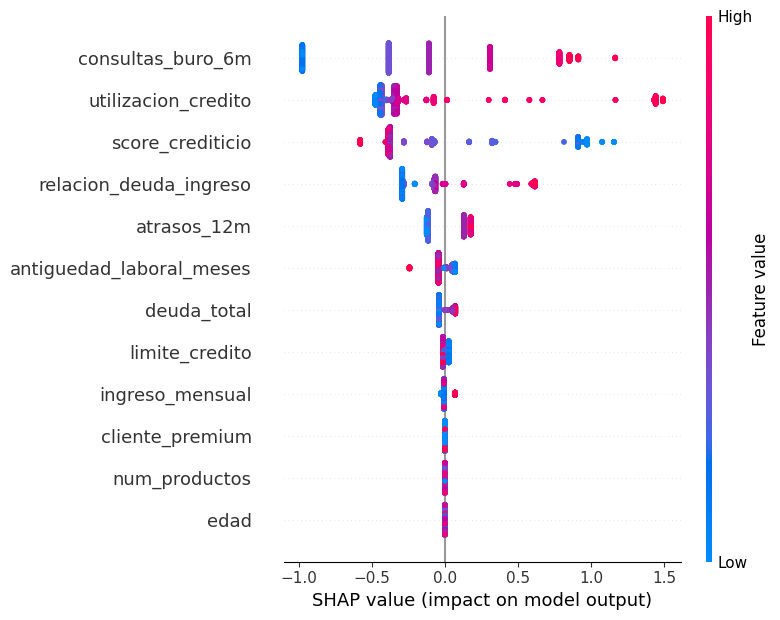

In [31]:
# Se selecciona XGBoost como mejor modelo
MEJOR = "XGBoost"
modelo_final = busquedas[MEJOR].best_estimator_.named_steps["modelo"]
umbral_final = umbral_optimo[MEJOR]

# Importancia de factores con SHAP sobre el test
explainer_final = shap.TreeExplainer(modelo_final)
shap_final = explainer_final.shap_values(X_te)

shap.summary_plot(shap_final, X_te)

In [32]:
# Importancia promedio (|SHAP| medio) por variable
importancia_shap = (pd.Series(np.abs(shap_final).mean(axis=0), index=X_te.columns)
                    .sort_values(ascending=False))
(importancia_shap / importancia_shap.sum()).rename("Peso relativo").to_frame().style.format("{:.1%}")

,Peso relativo
consultas_buro_6m,25.9%
utilizacion_credito,24.9%
score_crediticio,23.3%
relacion_deuda_ingreso,12.6%
atrasos_12m,6.8%
antiguedad_laboral_meses,2.7%
deuda_total,2.4%
limite_credito,0.8%
ingreso_mensual,0.6%
edad,0.0%


Se observa que las primeras 4 variables concentran aproximadamente el 87% del peso del modelo. Revisemos brevemente las variables:
1. Consultas al buró en los últimos 6 meses (consultas_buro_6m): Un mayor número de consultas quieren decir que el cliente anda buscando crédito en varias instituciones, lo que suele ser señal de necesidad de liquidez o la negación de un crédito en otro lado.
2. Utilización de crédito (utilizacion_credito): Un cliente que utiliza toda la línea de sus tarjetas tiene poco margen para soportar cualquier imprevisto.
3. Score crediticio (score_crediticio): Resume el historial de pago del cliente a través de un puntaje. Mayor puntaje (o mejor calificación) reduce el riesgo.
4. Relación deuda/ingreso (relacion_deuda_ingreso): Compara lo que el cliente debe contra lo que gana. Cuando la deuda es mayor que el ingreso mensual, el riesgo crediticio incrementa.

PI estimada del cliente: 13.8%  |  umbral: 0.17  ->  APROBAR  |  REAL: pagó


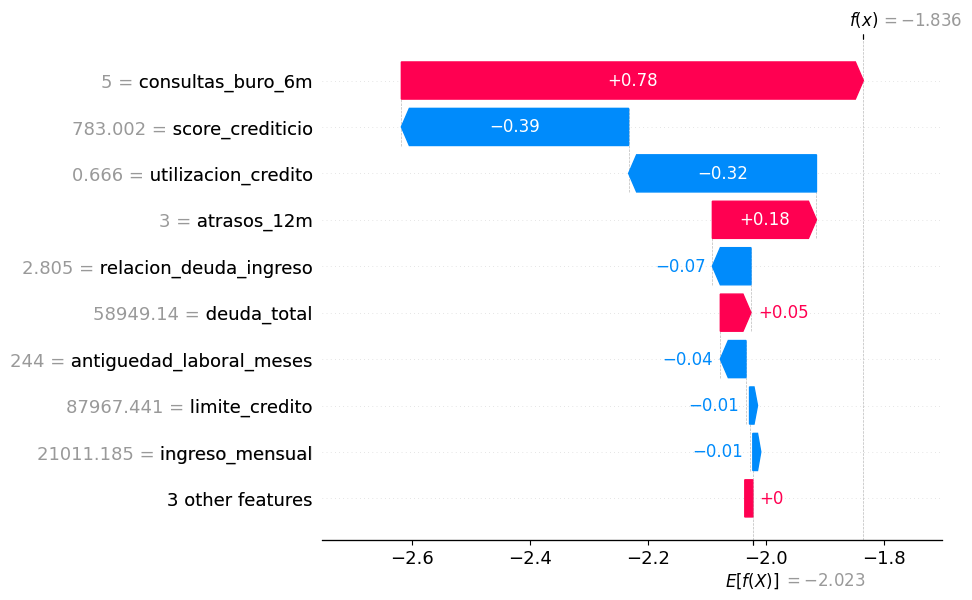

In [33]:
# Se analiza un cliente en particular con el modelo corregido
cliente_c = X_te.iloc[[11]]
pd_cliente = modelo_final.predict_proba(cliente_c)[0, 1]
print(f"PI estimada del cliente: {pd_cliente:.1%}  |  umbral: {umbral_final:.2f}  ->  "
      f"{'APROBAR' if pd_cliente < umbral_final else 'RECHAZAR'}  |  REAL: "
      f"{'default' if y_te.iloc[11] == 1 else 'pagó'}")

shap.plots.waterfall(
    shap.Explanation(
        values=explainer_final.shap_values(cliente_c)[0],
        base_values=explainer_final.expected_value,
        data=cliente_c.iloc[0],
        feature_names=cliente_c.columns
    )
)

Para el cliente seleccionado se obtuvo una probabilidad de incumplimiento estimada de 13.8%. De acuerdo con el gráfico SHAP, las 5 consultas al buró y los 3 atrasos registrados son los principales factores que incrementan su riesgo. Por otro lado, su score crediticio y la utilización de crédito contribuyen a disminuir la predicción respecto al valor de referencia del modelo.

Como la probabilidad estimada es menor al umbral de 0.17, el modelo recomendaría aprobar la solicitud. En este caso, el cliente efectivamente no presentó incumplimiento, aunque este resultado individual no es suficiente para evaluar el desempeño general del modelo.

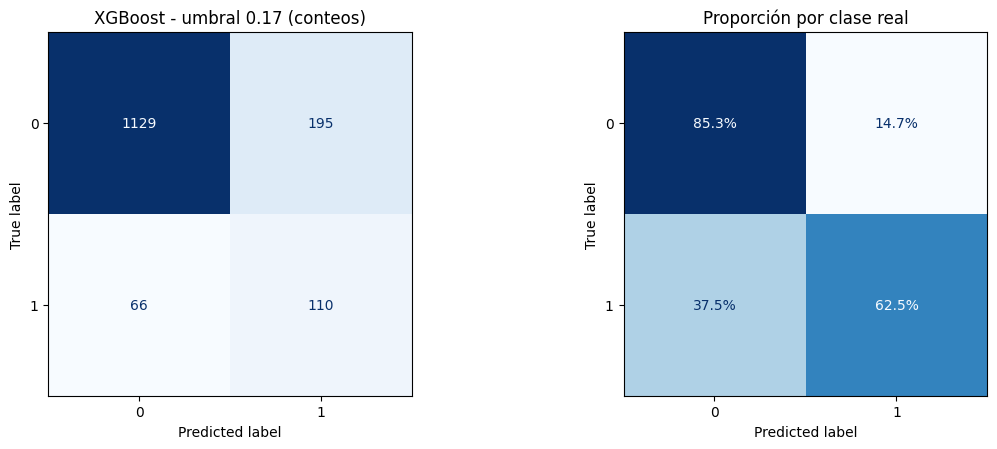

In [34]:
y_pred_final = (prob_te[MEJOR] >= umbral_final).astype(int)   # 1 = se rechaza por riesgo de default

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
ConfusionMatrixDisplay.from_predictions(y_te, y_pred_final,
                                        cmap=plt.cm.Blues, ax=axes[0], colorbar=False)
axes[0].set_title(f"{MEJOR} - umbral {umbral_final:.2f} (conteos)")
ConfusionMatrixDisplay.from_predictions(y_te, y_pred_final,
                                        cmap=plt.cm.Blues, ax=axes[1], colorbar=False,
                                        normalize="true", values_format=".1%")
axes[1].set_title("Proporción por clase real")
plt.tight_layout()
plt.show()

# **Conclusiones particulares:**



**Incluye un reporte de los resultados obtenidos dirigido al CEO de la fintech con las sugerencias y conclusiones en relación a cuál modelo desplegar.**

### +++++++++++ Inicia sección de Conclusiones Particulares ++++++++++++++++

# **Reporte ejecutivo: resultados de la auditoría del modelo de riesgo crediticio**

Al revisar la propuesta desarrollada por el analista junior, se concluye que los modelos originales no se encuentran en condiciones de implementarse en producción, debido a que se observaron inconsistencias metodológicas que reflejan un impacto en la confiabilidad de sus resultados.

El principal problema identificado fue la utilización de una variable que contiene información de los 30 días posteriores a la evaluación del crédito. Esto significa que los modelos estaban utilizando información que todavía no estaría disponible al momento de tomar una decisión. La evidencia de esto es que los tres modelos alcanzaron un accuracy del 100%, resultado que no representa su verdadera capacidad para predecir incumplimientos.

Por otra parte, en la preparación de los datos, se observa la aplicación del balanceo antes de separar los conjuntos de entrenamiento y prueba. Esto provocó que el conjunto de prueba incluyera clientes sintéticos y una proporción de incumplimientos distinta de la cartera real, afectando la confiabilidad de las evaluaciones.


**Resultados de la propuesta corregida**

Para atender estas observaciones, se desarrolló una nueva propuesta en la que se descartó la variable con fuga de información, se corrigió la preparación de los datos y se implementaron procedimientos de validación cruzada y ajuste de hiperparámetros.

Después de comparar los tres modelos, se observa que XGBoost obtuvo mejor desempeño con AUC ROC de 0.814 y Gini de 0.627, lo que indica una capacidad de discriminación razonable. Sin embargo, todavía puede cometer errores al identificar clientes con riesgo de incumplimiento.

Desde la perspectiva del negocio, se encontró que utilizar el umbral estándar de 0.5 no era la mejor alternativa. Considerando una utilidad de \$100 USD por cada cliente que paga correctamente y una pérdida de \$500 USD por cada cliente que incumple, se determinó un umbral de clasificación de 0.17, que permite obtener una mayor utilidad estimada.

Con este umbral, XGBoost aprobaría aproximadamente el 79.7% de las solicitudes y detectaría el 62.5% de los incumplimientos. Entre las solicitudes aprobadas, la tasa de incumplimiento observada sería de aproximadamente 5.5%, frente al 11.7% registrado en la cartera original.

**Impacto económico estimado**

Los resultados obtenidos muestran que la selección del umbral tiene un impacto importante en la rentabilidad esperada de la organización.

Escenario | Utilidad estimada por cada 10,000 solicitudes

**1. Aprobar todas las solicitudes:** \$296,000 USD

**2. XGBoost con umbral de 0.5:** \$373,333 USD

**3. XGBoost con umbral de 0.17:** \$532,667 USD

Se observa que el umbral optimizado permitiría incrementar la utilidad estimada en \$159,334 USD por cada 10,000 solicitudes evaluadas.

Es importante señalar que estas cifras corresponden a estimaciones obtenidas con los datos históricos y los supuestos económicos del ejercicio. Por lo tanto, no representan ganancias garantizadas para la institución.

**Recomendaciones**

A partir de los resultados obtenidos, se recomienda considerar XGBoost como el modelo candidato para su implementación, pero no autorizar todavía su despliegue en producción.

Es conveniente verificar que todas las variables estén disponibles al momento de la evaluación, comprobar la calibración de las probabilidades estimadas y validar su desempeño con información de periodos más recientes.

Además, se recomienda confirmar los supuestos económicos utilizados para determinar el umbral de clasificación, realizar una validación independiente y establecer mecanismos de monitoreo que permitan identificar cambios en el comportamiento de la cartera y en el desempeño del modelo.

En conclusión, la auditoría permitió identificar los problemas que explicaban los resultados perfectos de la propuesta original y desarrollar una alternativa más confiable. A pesar de requerir validaciones adicionales, los resultados muestran que un modelo correctamente desarrollado y evaluado puede apoyar la toma de decisiones crediticias y contribuir a mejorar la rentabilidad.


### +++++++++++ Termina sección de conclusiones particulares ++++++++++++++

# **Conclusiones**

Incluye todos los comentarios y conclusiones de esta actividad. En particular, responde sobre los siguientes puntos:

* Indica en qué casos el uso de LLMs fue de mayor provecho.
* En cuáles casos tu intervención como experto en combinación con los LLM fue importante para alcanzar con los objetivos propuestos.


### +++++++++++ Inicia sección de Conclusiones Finales ++++++++++++++++

Con el ejercicio de esta semana, logré comprender la importancia de revisar a detalle los resultados de un modelo y la forma en que fue desarrollado y evaluado. A pesar de tener un accuracy del 100%, se demostró que estos resultados se debían a problemas en la selección de variables y en la preparación de los datos, por lo que un alto nivel de desempeño no significa que un modelo sea confiable.

Debemos verificar que la información utilizada esté disponible al momento de realizar las predicciones, que los conjuntos de entrenamiento y prueba sean independientes y que las métricas seleccionadas correspondan al problema que se busca resolver. Además de los resultados estadísticos, es importante conocer los objetivos del negocio para tomar mejores decisiones fundamentadas en los datos.

Durante el desarrollo de la actividad utilicé Claude Opus 5.5 como herramienta de apoyo para revisar el código, identificar posibles errores metodológicos y desarrollar algunas de las correcciones propuestas. Considero que fue de mayor provecho para la generación y explicación de código en Python, así como para organizar los hallazgos y presentar los resultados de una manera más clara.

Sin embargo, considero que mi participación y criterio fueron fundamentales para interpretar y validar las propuestas generadas por la IA. Por ejemplo, identificar que una variable contenía información posterior a la evaluación del crédito requería comprender el contexto del problema y reconocer que esos datos no estarían disponibles al momento de tomar una decisión.

De igual manera, fue necesario seleccionar las métricas de evaluación, interpretar las diferencias entre entrenamiento y validación, y determinar qué recomendaciones resultaban más adecuadas desde la perspectiva del negocio.

El uso de la IA permitió agilizar algunas actividades, pero fue necesario revisar el código, ejecutar las pruebas y comprobar que los resultados fueran consistentes con los objetivos del ejercicio.

**Declaración de uso de IA**

Anthropic. (2026). Claude (Versión Opus 5.5) [Modelo grande de lenguaje], utilizado para consulta y generación de código. https://claude.ai/

### +++++++++++ Termina sección de conclusiones finales ++++++++++++++




# **<<< Fin de la Actividad de la Semana - Modelos de Árboles >>>**